# 07 · Experimento natural: el desgaste del rodillo del Skinpass

**Proyecto:** Análisis experimental MC4–Skinpass · Ternium Pesquería · producción 2025
**Fase:** 5 (análisis causal con datos históricos)

## A. Contexto de la etapa

**¿Qué investigamos?** Si el **desgaste del rodillo de trabajo** del Skinpass cambia el esfuerzo y los defectos. Es la parte del bloque Skinpass que mejor se presta a un diseño causal con datos históricos:
- Dentro de una campaña, el rodillo es el mismo y se va usando pieza a pieza.
- A lo largo del año, el mismo rodillo físico vuelve rectificado (más delgado) muchas veces.

**¿Por qué es un "experimento natural"?** Nadie decide la posición de una pieza en la campaña por cómo llegó del MC4: la decide el programa, que ordena sobre todo por ancho. Si comparamos piezas del **mismo producto y del mismo rango de ancho**, dentro de la **misma campaña**, la posición funciona casi como un tratamiento asignado por el calendario.

**Lo que sabemos:**
- **Notebook 01:** ΔFuerza parecía subir ~190 kN a lo largo de la campaña.
- **Notebook 02:** casi todo era el orden de anchos; quedaba un efecto en las primeras 10 piezas (~−50 kN).
- **Notebook 06:** las estimaciones causales sobre defectos fallan los controles negativos, salvo cuando la variación es "como asignada al azar". Este diseño busca justo eso.

**Pregunta para la planta:** ¿conviene cambiar el rodillo más seguido, o "asentarlo" con piezas menos exigentes al inicio de la campaña?

## B. Fundamento conceptual

**1. Efectos fijos.** Un efecto fijo de campaña es una constante propia de cada campaña: absorbe todo lo que las piezas de esa campaña comparten (el rodillo, su diámetro, el turno, el día, el tipo de mezcla programada). El efecto de la posición se estima entonces **solo con comparaciones dentro de la misma campaña**. Agregamos efectos fijos de:
- **producto × rango de ancho:** las piezas comparadas son del mismo tipo;
- **operador:** puede cambiar dentro de una campaña.

**2. Estudio de eventos por tramos.** En lugar de suponer que el desgaste es una recta, estimamos un efecto por **tramo de posición** (1-10, 11-20, …) contra un tramo de referencia (21-40). Si el desgaste importa, el patrón de los coeficientes lo mostrará: por ejemplo, un "asentamiento" al inicio y una meseta después.

**3. Proyecciones alternadas.** Con tres conjuntos de efectos fijos (~668 campañas, ~1,500 combinaciones producto × ancho, ~16 operadores), crear una columna por nivel sería enorme. Usamos el teorema de Frisch-Waugh-Lovell: restar repetidamente la media de cada grupo, por turnos, hasta que no cambie. Luego se corre una regresión normal sobre lo que queda.

**4. Errores agrupados por campaña.** Las piezas de una campaña no son independientes. El error estándar se calcula sumando primero por campaña (estimador sándwich por conglomerados).

**5. Prueba placebo.** La posición en la campaña **no puede** cambiar lo que el rollo trae del MC4 (su corona, sus temperaturas, su espera). Si el modelo encuentra "efectos" de la posición sobre esas variables, el orden de las piezas no es casi aleatorio dentro de la campaña y el diseño falla.

**6. Vida del rodillo.** Para el diámetro (que baja con cada rectificado) usamos efectos fijos de **rodillo físico**: comparamos el mismo rodillo consigo mismo a distintos diámetros. Agregamos efectos fijos de **mes**, porque el diámetro baja con el tiempo y cualquier tendencia del año se confundiría con él.

## C. Objetivo y metodología

| # | Análisis | Identificación | Resultados |
|---|---|---|---|
| 1 | Posición en la campaña (tramos) | EF campaña + producto × ancho + operador; ancho continuo | ΔFuerza, ΔBending, fuerza y bending reales |
| 2 | Placebo | Mismo modelo | Corona relativa, error de enrollado, caída F1→F7, días de espera |
| 3 | Defectos | Mismo modelo (probabilidad lineal) | B2 y B2 · forma |
| 4 | Vida del rodillo (diámetro) | EF rodillo físico + producto × ancho + operador + mes | ΔFuerza, ΔBending, B2 |

**Población:** modo Elongación (población A), entrenamiento.

## D. Implementación
### 0. Configuración

In [1]:
# Solo en Colab: descarga el repo (datos incluidos) e instala dependencias. En local no hace nada.
import os, sys, subprocess
if 'google.colab' in sys.modules:
    REPO = '/content/Entregable_Reto'
    if os.path.exists(REPO):
        # La copia de Colab es desechable: se iguala a GitHub aunque tenga figuras o archivos regenerados.
        subprocess.run(['git', '-C', REPO, 'fetch', '-q', 'origin', 'main'], check=True)
        subprocess.run(['git', '-C', REPO, 'reset', '-q', '--hard', 'origin/main'], check=True)
    else:
        subprocess.run(['git', 'clone', '-q', 'https://github.com/DiegoLarrieta/Entregable_Reto.git', REPO], check=True)
    subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', '-r', f'{REPO}/requirements.txt'], check=True)
    os.chdir(f'{REPO}/notebooks')

In [2]:
import sys, warnings
from pathlib import Path
RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src' / 'ternium.py').exists())
sys.path.append(str(RAIZ))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from src.ternium import *

warnings.filterwarnings('ignore')
estilo()
pd.set_option('display.max_columns', 30, 'display.width', 170)
RESULTADOS = RAIZ / 'resultados'; RESULTADOS.mkdir(exist_ok=True)

In [3]:
B = cargar_base_analitica()
d = B[(B['pob_A'] == 1) & (~B['en_prueba'])].reset_index(drop=True)
d['prod_ancho'] = d['producto'] + ' | ' + d['rango_ancho']
d['mes'] = d['fecha'].dt.month.astype(str)
TRAMOS = [0, 10, 20, 40, 60, 80, 120, 2000]
NOMBRES = ['1-10', '11-20', '21-40', '41-60', '61-80', '81-120', '>120']
REF = '21-40'
d['tramo'] = pd.cut(d['piezas_en_campana'], TRAMOS, labels=NOMBRES).astype(str)
DUM = [f'tramo_{t}' for t in NOMBRES if t != REF]
for t in NOMBRES:
    if t != REF:
        d[f'tramo_{t}'] = (d['tramo'] == t).astype(float)
print(f"Piezas: {len(d):,} · campañas: {d.campana.nunique()} · producto×ancho: {d.prod_ancho.nunique()} · operadores: {d.usuario_skp.nunique()} · rodillos físicos: {d.rodillo.nunique()}")
print(d['tramo'].value_counts().reindex(NOMBRES).to_dict())

Piezas: 43,175 · campañas: 581 · producto×ancho: 1552 · operadores: 15 · rodillos físicos: 34
{'1-10': 5646, '11-20': 5412, '21-40': 10143, '41-60': 8953, '61-80': 6912, '81-120': 4461, '>120': 1648}


In [4]:
def demean(df, cols, fes, tol=1e-8, max_iter=200):
    # Proyecciones alternadas: resta la media de cada efecto fijo por turnos hasta converger (Frisch-Waugh-Lovell).
    X = df[cols].astype(float).values.copy()
    codigos = [pd.factorize(df[f])[0] for f in fes]
    for _ in range(max_iter):
        previo = X.copy()
        for c in codigos:
            sumas = np.zeros((c.max() + 1, X.shape[1])); np.add.at(sumas, c, X)
            X -= (sumas / np.bincount(c)[:, None])[c]
        if np.abs(X - previo).max() < tol:
            break
    return X

def ef_ols(df, y, xs, fes, cluster):
    sub = df.dropna(subset=[y] + xs).reset_index(drop=True)
    Z = demean(sub, [y] + xs, fes)
    yy, XX = Z[:, 0], Z[:, 1:]
    XtX_inv = np.linalg.pinv(XX.T @ XX)
    beta = XtX_inv @ XX.T @ yy
    u = yy - XX @ beta
    g = pd.factorize(sub[cluster])[0]; G = g.max() + 1
    S = np.zeros((G, XX.shape[1])); np.add.at(S, g, XX * u[:, None])
    V = XtX_inv @ (S.T @ S) @ XtX_inv * G / (G - 1)
    se = np.sqrt(np.diag(V))
    return pd.DataFrame({'coef': beta, 'ee': se, 'bajo': beta - 1.96 * se, 'alto': beta + 1.96 * se}, index=xs), len(sub)

### 1. Posición en la campaña
Cada coeficiente es la diferencia del tramo respecto al tramo 21-40, comparando piezas de la misma campaña, del mismo producto y rango de ancho, y del mismo operador, con el ancho exacto como control.

In [5]:
FES = ['campana', 'prod_ancho', 'usuario_skp']
RESP = {'delta_fuerza': 'ΔFuerza (kN)', 'delta_bending': 'ΔBending (kN)', 'fuerza_real': 'Fuerza real (kN)', 'bending_real': 'Bending real (kN)',
        'preset_bending': 'Preset de bending (kN)'}
res_pos = {}
for r in RESP:
    t, n = ef_ols(d, r, DUM + ['ancho_mm'], FES, 'campana')
    res_pos[r] = t.loc[DUM]
tab_pos = pd.concat({RESP[r]: v['coef'] for r, v in res_pos.items()}, axis=1)
tab_pos.index = [i.replace('tramo_', '') for i in tab_pos.index]
pd.concat({RESP[r]: v[['coef', 'bajo', 'alto']] for r, v in res_pos.items()}, axis=1).round(1).to_csv(RESULTADOS / '07_posicion_campana.csv')
tab_pos.round(1)

,ΔFuerza (kN),ΔBending (kN),Fuerza real (kN),Bending real (kN),Preset de bending (kN)
1-10,-97.8,15.0,-77.8,85.6,70.5
11-20,-23.9,-4.5,-20.7,30.0,34.4
41-60,20.7,0.2,7.1,-29.7,-29.9
61-80,25.9,3.8,8.5,-44.5,-48.2
81-120,41.4,-4.7,14.0,-31.9,-27.2
>120,27.1,-10.1,11.2,-21.2,-11.1


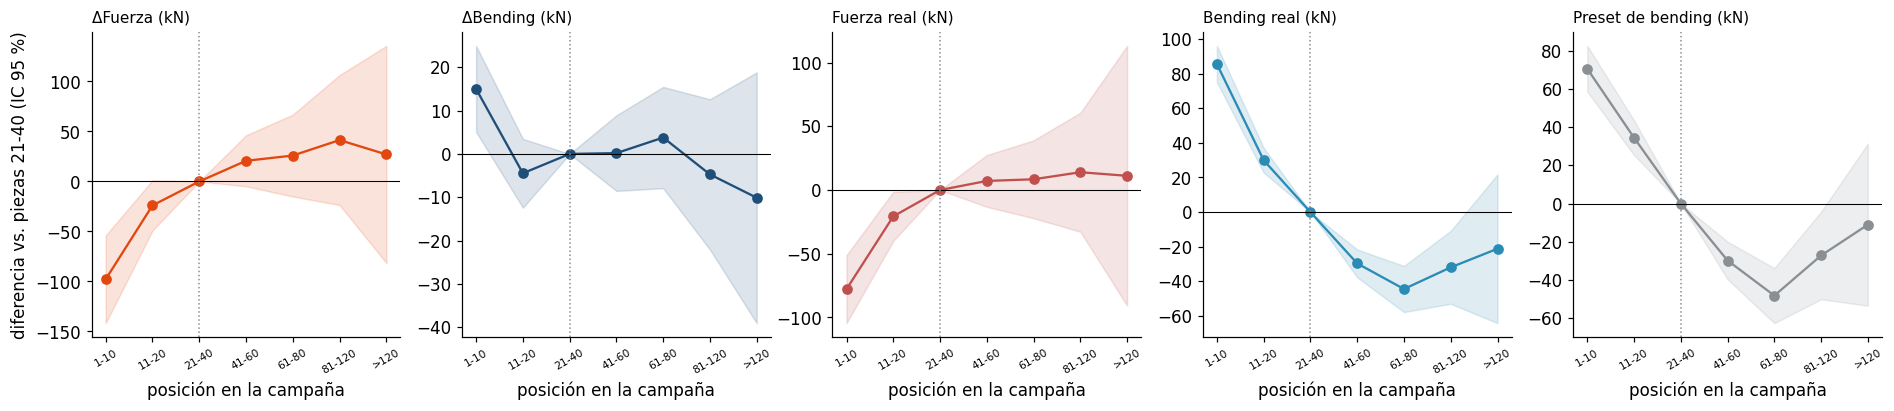

In [6]:
def estudio_eventos(res, titulos, nombre, ylab, colores=None):
    fig, ax = plt.subplots(1, len(res), figsize=(4.2 * len(res), 3.6))
    ax = np.atleast_1d(ax)
    for k, (a, (r, t)) in enumerate(zip(ax, res.items())):
        t = t.copy(); t.index = [i.replace('tramo_', '') for i in t.index]
        t.loc[REF] = [0, 0, 0, 0]; t = t.loc[NOMBRES]
        x = np.arange(len(t)); c = (colores or [COLORES['azul']] * len(res))[k]
        a.fill_between(x, t.bajo, t.alto, color=c, alpha=.15); a.plot(x, t.coef, 'o-', color=c)
        a.axhline(0, color='k', lw=.7); a.axvline(NOMBRES.index(REF), color=COLORES['gris'], ls=':', lw=1)
        a.set_xticks(x); a.set_xticklabels(NOMBRES, fontsize=7, rotation=30); a.set_title(titulos[r], fontsize=10)
        a.set_xlabel('posición en la campaña')
    ax[0].set_ylabel(ylab)
    guardar(fig, nombre); plt.show()

estudio_eventos(res_pos, RESP, '07_posicion_esfuerzo', 'diferencia vs. piezas 21-40 (IC 95 %)',
                [COLORES['naranja'], COLORES['azul'], COLORES['rojo'], '#2a8bb5', COLORES['gris']])

**Cómo leerlo.** Cada punto es cuánto cambia la respuesta en ese tramo frente al tramo 21-40 (línea punteada). La banda es el intervalo de confianza del 95 %. Una curva plana pegada al 0 significa que la posición, y por tanto el desgaste dentro de la campaña, no mueve esa respuesta.

### 2. Placebo: la posición no puede cambiar lo que trae el rollo
Si el orden dentro de la campaña es "casi aleatorio" una vez controlado el producto y el ancho, la posición no debe predecir variables que se fijaron **antes** del Skinpass.

In [7]:
PLACEBO = {'corona_relativa_pct': 'Corona relativa (%)', 'error_t_enrollado_c': 'Error de enrollado (°C)',
           'caida_f1_f7_c': 'Caída F1→F7 (°C)', 'dias_mc4_skp': 'Días MC4 → SKP'}
res_pla = {}
for r in PLACEBO:
    t, n = ef_ols(d, r, DUM + ['ancho_mm'], FES, 'campana')
    sd = (d[r] - d.groupby('prod_ancho')[r].transform('mean')).std()
    res_pla[r] = t.loc[DUM] / sd                   # en desviaciones estándar, para comparar entre variables
tab_pla = pd.concat({PLACEBO[r]: v['coef'] for r, v in res_pla.items()}, axis=1)
tab_pla.index = [i.replace('tramo_', '') for i in tab_pla.index]
tab_pla.round(3).to_csv(RESULTADOS / '07_placebo.csv')
print('Coeficientes en desviaciones estándar (dentro de producto × ancho):')
tab_pla.round(3)

Coeficientes en desviaciones estándar (dentro de producto × ancho):


,Corona relativa (%),Error de enrollado (°C),Caída F1→F7 (°C),Días MC4 → SKP
1-10,-0.040,0.029,-0.033,-0.062
11-20,-0.031,0.014,-0.029,-0.031
41-60,0.065,-0.007,-0.018,0.006
61-80,0.099,-0.021,-0.055,0.018
81-120,0.177,-0.018,-0.050,0.073
>120,-0.021,-0.051,-0.006,-0.081


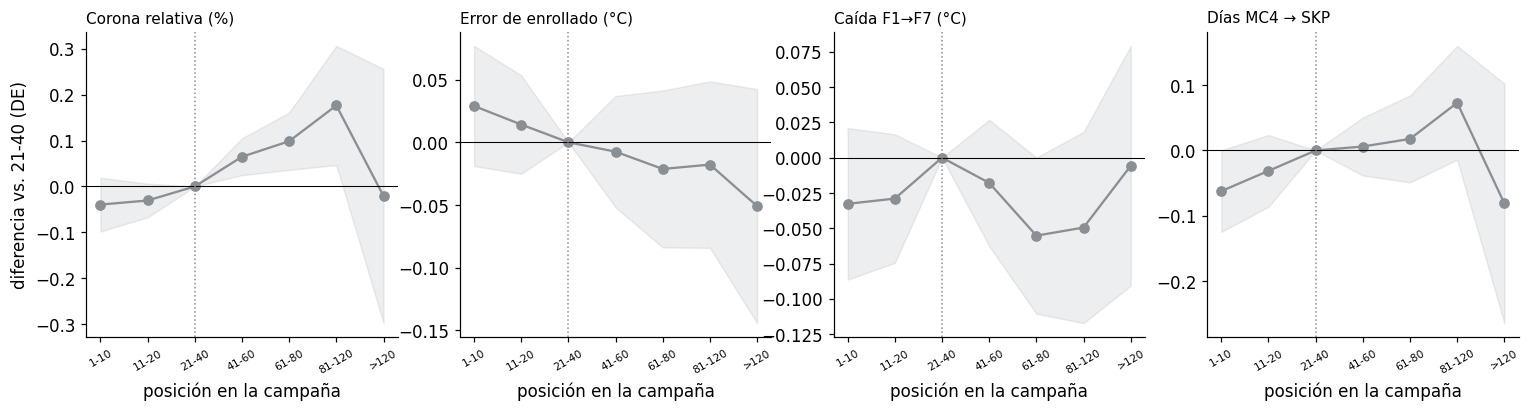

In [8]:
estudio_eventos(res_pla, PLACEBO, '07_placebo', 'diferencia vs. 21-40 (DE)', [COLORES['gris']] * 4)

**Cómo leerlo.** Aquí la escala está en **desviaciones estándar** de cada variable, para poder comparar. Lo esperado es que todo quede pegado al 0. Un tramo que se separe indica que, en esa parte de la campaña, se programan rollos sistemáticamente distintos, y el efecto de la posición sobre el esfuerzo podría ser esa diferencia y no el desgaste.

### 3. Defectos según la posición en la campaña (modelo de probabilidad lineal)

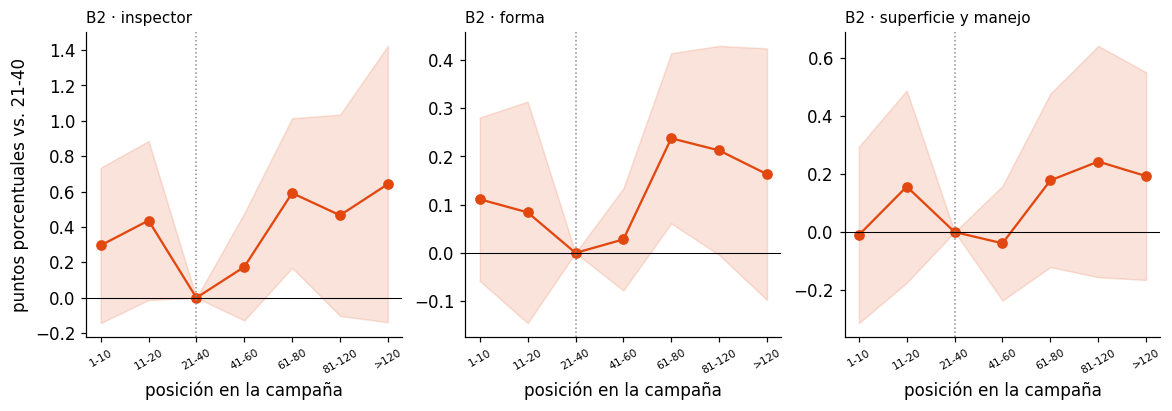

b2               b2_forma               b2_superficie_manejo              
               coef   bajo   alto     coef   bajo   alto                 coef   bajo   alto
tramo_1-10    0.296 -0.143  0.735    0.111 -0.058  0.281               -0.010 -0.314  0.294
tramo_11-20   0.436 -0.013  0.886    0.084 -0.145  0.314                0.157 -0.175  0.488
tramo_41-60   0.174 -0.128  0.477    0.028 -0.078  0.134               -0.039 -0.236  0.159
tramo_61-80   0.592  0.169  1.015    0.238  0.061  0.414                0.178 -0.121  0.477
tramo_81-120  0.466 -0.103  1.035    0.213 -0.004  0.429                0.243 -0.156  0.642
tramo_>120    0.642 -0.139  1.423    0.163 -0.098  0.424                0.193 -0.165  0.551

In [9]:
res_def = {}
for r, nom in [('b2', 'B2 · inspector (pp)'), ('b2_forma', 'B2 · forma (pp)'), ('b2_superficie_manejo', 'B2 · superficie (pp)')]:
    t, n = ef_ols(d.assign(**{r: 100 * d[r]}), r, DUM + ['ancho_mm'], FES, 'campana')
    res_def[r] = t.loc[DUM]
estudio_eventos(res_def, {'b2': 'B2 · inspector', 'b2_forma': 'B2 · forma', 'b2_superficie_manejo': 'B2 · superficie y manejo'},
                '07_posicion_defectos', 'puntos porcentuales vs. 21-40', [COLORES['naranja']] * 3)
pd.concat({k: v[['coef', 'bajo', 'alto']] for k, v in res_def.items()}, axis=1).round(3)

**¿La subida de defectos de forma se explica por el menor bending?** Repetimos el modelo de forma agregando el bending real como control. Si el coeficiente de los tramos tardíos baja, parte de la subida pasa por el bending. Es solo una pista: el bending es un mediador posible, no un confusor.

In [10]:
dd = d.assign(b2_forma=100 * d['b2_forma'])
t_sin, _ = ef_ols(dd, 'b2_forma', DUM + ['ancho_mm'], FES, 'campana')
t_con, _ = ef_ols(dd, 'b2_forma', DUM + ['ancho_mm', 'bending_real', 'fuerza_real'], FES, 'campana')
comp = pd.DataFrame({'forma (pp), sin controlar bending': t_sin.loc[DUM, 'coef'],
                     'forma (pp), controlando bending y fuerza reales': t_con.loc[DUM, 'coef']})
comp.index = [i.replace('tramo_', '') for i in comp.index]
print(f"Coeficiente del bending real en el modelo de forma: {t_con.loc['bending_real', 'coef'] * 100:.3f} pp por 100 kN "
      f"(IC {t_con.loc['bending_real', 'bajo'] * 100:.3f} a {t_con.loc['bending_real', 'alto'] * 100:.3f})")
comp.round(3)

Coeficiente del bending real en el modelo de forma: -0.063 pp por 100 kN (IC -0.119 a -0.007)


,"forma (pp), sin controlar bending","forma (pp), controlando bending y fuerza reales"
1-10,0.111,0.166
11-20,0.084,0.103
41-60,0.028,0.009
61-80,0.238,0.210
81-120,0.213,0.192
>120,0.163,0.150


### 4. Vida del rodillo: el mismo rodillo físico a distintos diámetros
Cada rectificado le quita diámetro. Comparamos el mismo rodillo consigo mismo (efecto fijo de rodillo), en piezas del mismo producto × ancho y del mismo operador, controlando el mes.

In [11]:
d['diametro_10mm'] = d['diametro_rodillo_mm'] / 10
vida = d.groupby('rodillo').agg(campanas=('campana', 'nunique'), diam_max=('diametro_rodillo_mm', 'max'), diam_min=('diametro_rodillo_mm', 'min'))
print(f"Rodillos con ≥ 5 campañas: {(vida.campanas >= 5).sum()} · rango de diámetro dentro de rodillo (mediana): {(vida.diam_max - vida.diam_min).median():.1f} mm")
filas = []
for r, nom, esc in [('delta_fuerza', 'ΔFuerza (kN)', 1), ('delta_bending', 'ΔBending (kN)', 1), ('fuerza_real', 'Fuerza real (kN)', 1),
                    ('b2', 'B2 · inspector (pp)', 100), ('b2_forma', 'B2 · forma (pp)', 100)]:
    t, n = ef_ols(d.assign(**{r: esc * d[r]}), r, ['diametro_10mm', 'ancho_mm', 'piezas_en_campana'],
                  ['rodillo', 'prod_ancho', 'usuario_skp', 'mes'], 'campana')
    filas.append({'resultado': nom, 'efecto de −10 mm de diámetro': -t.loc['diametro_10mm', 'coef'],
                  'IC bajo': -t.loc['diametro_10mm', 'alto'], 'IC alto': -t.loc['diametro_10mm', 'bajo'], 'piezas': n})
tab_vida = pd.DataFrame(filas)
tab_vida.round(3).to_csv(RESULTADOS / '07_vida_rodillo.csv', index=False)
tab_vida.round(3)

Rodillos con ≥ 5 campañas: 30 · rango de diámetro dentro de rodillo (mediana): 11.4 mm


,resultado,efecto de −10 mm de diámetro,IC bajo,IC alto,piezas
0,ΔFuerza (kN),-16.972,-67.111,33.167,43175
1,ΔBending (kN),7.129,-14.579,28.837,43175
2,Fuerza real (kN),-27.295,-75.461,20.870,43175
3,B2 · inspector (pp),-0.038,-0.523,0.447,43175
4,B2 · forma (pp),0.058,-0.170,0.286,43175


**Cómo leerlo.** Cada fila es cuánto cambia la respuesta cuando el mismo rodillo tiene 10 mm menos de diámetro, es decir, después de varios rectificados. Un rodillo pierde en mediana unos milímetros a lo largo del año, así que 10 mm representa casi toda su vida útil en estos datos.

## E. Interpretación de los resultados

**1. El desgaste dentro de la campaña sí mueve el esfuerzo, sobre todo al inicio.** Comparando piezas de la misma campaña, del mismo producto × ancho y del mismo operador:
- **Fuerza real:** en las primeras 10 piezas es **78 kN menor** que en las piezas 21-40 (IC −105 a −51). Después de la pieza 20 queda prácticamente plana. Un rodillo recién montado (más rugoso) necesita menos fuerza para la misma elongación, y se "asienta" en unas 20 piezas.
- **ΔFuerza:** −98 kN en las primeras 10 piezas. El preset no anticipa ese asentamiento: **pide de más al inicio de cada campaña**.
- **Bending real:** es el efecto más fuerte y más preciso. Baja de **+86 kN** (piezas 1-10) a **−45 kN** (piezas 61-80) respecto al tramo 21-40, unos 130 kN a lo largo de la campaña.
- **Preset de bending:** sigue exactamente la misma curva (+70 → −48 kN). Por eso **ΔBending queda plano**: el setup ya programa menos bending conforme avanza la campaña, probablemente para compensar el desgaste o la corona térmica del rodillo.

**2. El placebo pasa en tres de cuatro variables.** La posición casi no "predice" el error de enrollado, la caída F1→F7 ni los días de espera (todo |coef| < 0.08 DE). La **corona relativa sí sube** en la segunda mitad (+0.10 a +0.18 DE en las piezas 61-120): en esa parte se programan rollos con un poco más de corona, aun dentro del mismo producto × ancho. Como la corona casi no mueve la fuerza (0.04 DE por DE, Notebook 06), el sesgo sobre el esfuerzo es despreciable (~5 kN). Sobre los defectos de forma **sí podría importar**, porque la cola de corona se asocia con forma (Notebook 05).

**3. Los defectos de forma suben en la segunda mitad de la campaña.** Frente a las piezas 21-40: **+0.24 pp en 61-80** (IC 0.06 a 0.41) y +0.21 pp en 81-120 (IC −0.00 a 0.43). Con un riesgo base de ~0.24 %, eso es **aproximadamente el doble de riesgo**. B2 total sube de forma parecida (+0.59 pp en 61-80, IC 0.17 a 1.02).
- *Cautela:* son 18 comparaciones (6 tramos × 3 resultados); una o dos "significativas" podrían ser azar. El patrón, sin embargo, es consistente entre tramos (61-80, 81-120, >120) y entre resultados.
- *Cautela:* la corona también sube en esos tramos (placebo).

**4. ¿La subida de forma pasa por el bending?** Dentro de la misma campaña, más bending real se asocia con menos forma: **−0.06 pp por cada 100 kN** (IC −0.12 a −0.01), el mismo signo que en los Notebooks 05 y 06. Pero controlar por el bending y la fuerza apenas cambia la subida en 61-80 (0.24 → 0.21 pp). **Lo que causa más defectos al final de la campaña no es, sobre todo, que se aplique menos bending.** Puede ser el desgaste mismo del rodillo (rugosidad, marcas) o la corona del material que se programa ahí.

**5. La vida del rodillo (diámetro) no se asocia con nada.** Comparando el mismo rodillo físico a distintos diámetros (mismo mes, producto × ancho y operador), 10 mm menos de diámetro no cambia ΔFuerza (−17 kN, IC −67 a 33), ΔBending, fuerza real ni defectos. El rectificado deja al rodillo "como nuevo": lo que importa es **cuánto se ha usado en la campaña actual**, no cuántas vidas lleva.

## F. Conclusiones de la etapa

### Respuesta del experimento natural
> **El desgaste del rodillo dentro de la campaña es un factor real del Skinpass.** Al inicio de cada campaña el rodillo necesita ~78 kN menos fuerza durante ~20 piezas, y el preset no lo anticipa (ΔFuerza −98 kN). El setup ya reduce el bending ~130 kN a lo largo de la campaña. Los defectos de forma se duplican en la segunda mitad de la campaña, sin que el menor bending lo explique. La vida acumulada del rodillo (diámetro) no importa.

### Hallazgos principales
1. **Asentamiento del rodillo:** −78 kN de fuerza real y −98 kN de ΔFuerza en las primeras 10 piezas; plano después de la 20.
2. **El bending se programa a la baja** en la campaña (preset y real, ~130 kN); ΔBending plano.
3. **Defectos de forma ×2 en la segunda mitad de la campaña** (piezas 61-120), con cautela por comparaciones múltiples y por el placebo de corona.
4. **Más bending, menos forma**, también dentro de campaña (−0.06 pp por 100 kN), pero no explica la subida tardía.
5. **El diámetro (vida del rodillo) no importa.**

### Implicaciones para planta
- **Corrección del preset de fuerza al inicio de campaña:** el error es sistemático y conocido (primeras ~20 piezas). Es una versión acotada y más concreta de la intervención D.
- **Duración de campaña y defectos de forma:** si la subida se confirma, cambiar el rodillo antes (por ejemplo, a las ~60 piezas) o programar al final de la campaña los productos menos sensibles a forma. Esto se puede probar en planta (Notebook 08).

### Limitaciones
- La posición en la campaña no se asigna al azar: el placebo de corona muestra algo de selección en la segunda mitad.
- Pocos defectos por tramo; 18 comparaciones.
- El diámetro varía poco dentro de cada rodillo (mediana 11 mm en el año).

### Qué sigue
El **Notebook 08** reúne la evidencia de todos los notebooks para elegir la intervención y escribir el protocolo del experimento en planta.